# Step 35 — Waveform review for files with multiple pick groups

Run after the updated step 32. This notebook plots **each waveform file with at least two associated source pick groups**. All workflow code is here; only configuration is imported. It writes a new timestamped review directory beneath the configured external `output_root`, without changing waveforms, picks or associations.

## Purpose and selection

A triggered recording can contain more than one earthquake. Multiple source groups can also describe the same earthquake from individual and monthly PHA records. These plots help distinguish separated arrivals, duplicate descriptions, source-group fragmentation and incorrect time-window matches. They do not automatically classify or split earthquakes.

The default selects all WAV+PICKS waveform IDs with at least two distinct `(pick_source, pick_group_id)` pairs. Set `REQUIRE_MULTIPLE_GROUPS_WITHIN_ONE_SOURCE=True` to require multiple groups within the individual or monthly source alone. The selection uses saved associations; newly converted files will be absent until stages 30/32 are rerun. No parser, conversion or association runs are triggered here.

Each trace segment is shown in its own panel, with time in seconds from the earliest trace start in that file. Different source groups receive different colors; P markers are solid and S markers dashed. Unknown phases use dotted markers. Original source group IDs are printed in the legend; traces keep their full SEED IDs. Signals are shown in saved sample units without filtering, normalization, resampling or response removal. Different panels have independent amplitude scales.

## PI2L markers, missing channels and clock uncertainty

The updated step-32 overlay columns are required: `waveform_seed_id`, `include_waveform_overlay` and `waveform_overlay_rule`. Original low-gain pick IDs/times remain in the audit, while approved PI2L markers target PI2Z/EHZ. Low-gain markers suppressed by existing PI2Z picks are logged but not drawn. These are display choices, not recovery of a missing low-gain signal or scientific reassignment of the pick.

Markers are drawn only on an **exact SEED-ID match** whose individual segment includes the pick time. Missing channels, picks outside matching segments, invalid times and suppressed markers are retained in per-pick audit CSVs, not silently discarded. File-wide association alone does not establish that the picked channel exists. Two trace segments of the same ID may each receive a marker if both span its time.

Recorded timestamps are represented as UTC by ObsPy/pandas without independently establishing their historical clock convention. No automatic offset/drift correction is applied. A short recording can omit an arrival, and a partial DMX recovery can omit channels or the end of the event. Review those cases explicitly; an absent visible signal alone does not invalidate a pick.

## 1. Configure the review

`MAX_FILES=None` processes the full selection. Set a small number for a first trial, or set `ONLY_WAVEFORM_IDS` to specific legacy waveform IDs such as `91060317` and `9106031E`. `MAX_INLINE_PLOTS` limits display only, not the number of files saved. Input paths come from the same conversion configuration as the other steps.

In [ ]:
from pathlib import Path
from datetime import datetime, timezone
import sys, json, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from obspy import read
from IPython.display import display, Image
_candidates = [Path.cwd(), Path.cwd() / '10_conversion', *Path.cwd().parents]
PIPELINE_DIR = next((p for p in _candidates if (p / 'pinatubo_steps').is_dir()), None)
if PIPELINE_DIR is None:
    raise FileNotFoundError('Start from the repository root or 10_conversion.')
if str(PIPELINE_DIR) not in sys.path:
    sys.path.insert(0, str(PIPELINE_DIR))
from pinatubo_steps.config import pipeline_paths
CONFIG_FILE = None
P = pipeline_paths(config_file=CONFIG_FILE)
PICK_MAP = Path(P['PICK_MAP_CSV'])
WAVEFORM_INDEX = Path(P['WAVEFORM_INDEX'])
REVIEW_ROOT = Path(P['OUTPUT_ROOT']) / 'waveform_pick_review' / 'step35'
MIN_PICK_GROUPS = 2
REQUIRE_MULTIPLE_GROUPS_WITHIN_ONE_SOURCE = False
ONLY_WAVEFORM_IDS = None  # Example: ['91060317', '9106031E']
MAX_FILES = None
MAX_INLINE_PLOTS = 99999 
FIG_DPI = 140
SAVE_PDF = False
print('Configuration:', P['CONFIG_FILE'])
print('Pick map:', PICK_MAP)
print('Waveform index:', WAVEFORM_INDEX)
print('Review output root:', REVIEW_ROOT)

Configuration: /Users/thompsong/Developer/Pinatubo1991SeismicData/10_conversion/conversion_config.json
Pick map: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/32_waveform_pick_event_map.csv
Waveform index: /Users/thompsong/work/Pinatubo1991Processing/converted/pipeline_tmp/10_waveform_index.csv
Review output root: /Users/thompsong/work/Pinatubo1991Processing/converted/waveform_pick_review/step35


## 2. Load saved associations and select recordings

Only picks classified WAV+PICKS are eligible. Selection occurs before suppressed PI2L markers are omitted, so no source group is hidden by the display policy. A record of the selection and input modification times is saved with each run. If overlay fields are absent, rerun the updated step 32 first rather than guessing a policy in this notebook.

The summary also reports how many current waveform IDs are absent from the saved association map. This count includes ordinary WAV_ONLY files, so it is not a staleness measure by itself. Use step 33/34 to compare the entire event catalogue against the waveform index.

In [2]:
def load_review_selection(pick_map_path, waveform_index_path, *, min_groups=2,
                          within_source=False, only_ids=None, max_files=None):
    picks = pd.read_csv(pick_map_path, dtype={'waveform_id': str, 'pick_group_id': str,
                                              'pick_id': str}, low_memory=False)
    required = {'event_class', 'waveform_id', 'pick_group_id', 'pick_source', 'pick_time',
                'waveform_seed_id', 'include_waveform_overlay', 'waveform_overlay_rule'}
    missing = required - set(picks.columns)
    if missing:
        raise ValueError(f'Missing step-32 columns {sorted(missing)}. Rerun the updated step 32 first.')
    waveforms = pd.read_csv(waveform_index_path, dtype={'event_id': str}, low_memory=False)
    if waveforms['event_id'].duplicated().any():
        raise ValueError('Waveform index has duplicate event IDs; resolve before plotting.')
    picks = picks[picks['event_class'].eq('WAV+PICKS')].copy()
    if picks[['waveform_id', 'pick_group_id', 'pick_source']].isna().any().any():
        raise ValueError('Associated picks have missing waveform or source-group identity.')
    picks['group_label'] = picks['pick_source'].astype(str) + ':' + picks['pick_group_id'].astype(str)
    distinct = picks[['waveform_id', 'pick_source', 'group_label']].drop_duplicates()
    counts = distinct.groupby('waveform_id').size().rename('n_pick_groups')
    selection = counts[counts.ge(min_groups)].to_frame()
    if within_source:
        same_source = distinct.groupby(['waveform_id', 'pick_source']).size().groupby(level=0).max()
        selection = selection.loc[selection.index.isin(same_source[same_source.ge(min_groups)].index)]
    selection = selection.join(waveforms.set_index('event_id'), how='left')
    selection = selection.sort_index()
    if only_ids is not None:
        selection = selection.loc[selection.index.isin([str(x) for x in only_ids])]
    if max_files is not None:
        if max_files < 0:
            raise ValueError('MAX_FILES must be nonnegative or None.')
        selection = selection.head(max_files)
    selection.index.name = 'waveform_id'
    return picks, selection

review_picks, selection = load_review_selection(
    PICK_MAP, WAVEFORM_INDEX, min_groups=MIN_PICK_GROUPS,
    within_source=REQUIRE_MULTIPLE_GROUPS_WITHIN_ONE_SOURCE,
    only_ids=ONLY_WAVEFORM_IDS, max_files=MAX_FILES)
print('Selected waveform files:', len(selection))
display(selection[['n_pick_groups', 'wav_file']].head(20))

Selected waveform files: 159


,n_pick_groups,wav_file
waveform_id,,
91050304,2,/Users/thompsong/work/Pinatubo1991Processing/c...
9105041O,2,/Users/thompsong/work/Pinatubo1991Processing/c...
91050701,2,/Users/thompsong/work/Pinatubo1991Processing/c...
9105071D,2,/Users/thompsong/work/Pinatubo1991Processing/c...
9105071J,2,/Users/thompsong/work/Pinatubo1991Processing/c...
91050801,2,/Users/thompsong/work/Pinatubo1991Processing/c...
9105081Y,2,/Users/thompsong/work/Pinatubo1991Processing/c...
91050901,2,/Users/thompsong/work/Pinatubo1991Processing/c...
9105090J,2,/Users/thompsong/work/Pinatubo1991Processing/c...


## 3. Plot one recording and audit every marker

This function reads a saved MiniSEED file and checks each marker against full trace ID and per-segment coverage. The audit assigns one status per pick: `plotted`, `suppressed_by_overlay_policy`, `missing_overlay_target`, `invalid_pick_time`, `missing_target_channel` or `outside_target_trace_window`. Raw IDs, groups and plotting targets remain in the table. The plot footer summarizes any omitted markers; the complete details are in CSV.

No arrival is moved to the nearest signal or nearest trace. The waveform file is only read. Failures propagate to the run loop, which records them and continues with other files.

In [3]:
def plot_waveform_groups(waveform_path, picks, output_png, *, dpi=140, save_pdf=False):
    stream = read(str(waveform_path))
    if not stream or not any(tr.stats.npts for tr in stream):
        raise ValueError('Waveform has no samples.')
    traces = sorted([tr for tr in stream if tr.stats.npts],
                    key=lambda tr: (tr.id, tr.stats.starttime))
    reference = min(tr.stats.starttime for tr in traces)
    labels = sorted(picks['group_label'].unique())
    colors = {label: plt.get_cmap('tab10')(i % 10) for i, label in enumerate(labels)}
    audit = picks.copy()
    audit['review_status'] = ''
    audit['plotted_trace_segments'] = 0
    audit['reference_time'] = str(reference)
    audit['marker_seconds'] = np.nan
    fig, axes = plt.subplots(len(traces), 1, sharex=True, squeeze=False,
                             figsize=(14, max(4, 1.7 * len(traces))))
    try:
        for ax, tr in zip(axes[:, 0], traces):
            x = tr.times() + float(tr.stats.starttime - reference)
            ax.plot(x, tr.data, color='0.25', linewidth=0.6)
            ax.set_ylabel('Saved samples')
            ax.text(0.005, 0.88, tr.id, transform=ax.transAxes, fontsize=9,
                    bbox=dict(facecolor='white', alpha=0.8, edgecolor='none'))
            ax.grid(axis='x', alpha=0.15)
        for index, row in audit.iterrows():
            enabled = str(row['include_waveform_overlay']).strip().lower() in ('true', '1', '1.0')
            if not enabled:
                audit.at[index, 'review_status'] = 'suppressed_by_overlay_policy'
                continue
            target = row['waveform_seed_id']
            if pd.isna(target) or not str(target).strip():
                audit.at[index, 'review_status'] = 'missing_overlay_target'
                continue
            timestamp = pd.to_datetime(row['pick_time'], utc=True, errors='coerce')
            if pd.isna(timestamp):
                audit.at[index, 'review_status'] = 'invalid_pick_time'
                continue
            from obspy import UTCDateTime
            pick_time = UTCDateTime(timestamp.to_pydatetime())
            marker = float(pick_time - reference)
            audit.at[index, 'marker_seconds'] = marker
            matching = [(ax, tr) for ax, tr in zip(axes[:, 0], traces) if tr.id == target]
            if not matching:
                audit.at[index, 'review_status'] = 'missing_target_channel'
                continue
            covered = [(ax, tr) for ax, tr in matching
                       if tr.stats.starttime <= pick_time <= tr.stats.endtime]
            if not covered:
                audit.at[index, 'review_status'] = 'outside_target_trace_window'
                continue
            phase = str(row.get('phase', '?')).strip().upper()
            style = '-' if phase == 'P' else '--' if phase == 'S' else ':'
            for ax, tr in covered:
                ax.axvline(marker, color=colors[row['group_label']], linestyle=style,
                           linewidth=1.1, alpha=0.85)
                ax.text(marker, 0.96, phase, color=colors[row['group_label']], fontsize=7,
                        transform=ax.get_xaxis_transform(), va='top')
            audit.at[index, 'review_status'] = 'plotted'
            audit.at[index, 'plotted_trace_segments'] = len(covered)
        handles = [Line2D([0], [0], color=colors[label], label=label, lw=2) for label in labels]
        handles += [Line2D([0], [0], color='black', linestyle='-', label='P'),
                    Line2D([0], [0], color='black', linestyle='--', label='S')]
        axes[0, 0].legend(handles=handles, loc='upper left', bbox_to_anchor=(1.01, 1), fontsize=8)
        axes[-1, 0].set_xlabel(f'Seconds from recorded trace reference {reference} (clock convention unverified)')
        waveform_id = str(picks['waveform_id'].iloc[0])
        statuses = audit['review_status'].value_counts().to_dict()
        fig.suptitle(f'{waveform_id}: {len(labels)} source pick groups — candidate multi-event recording')
        fig.text(0.01, 0.01, 'Marker audit: ' + '; '.join(f'{k}={v}' for k, v in statuses.items()), fontsize=8)
        fig.tight_layout(rect=(0, 0.05, 1, 0.95))
        output_png = Path(output_png)
        output_png.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(output_png, dpi=dpi)
        if save_pdf:
            fig.savefig(output_png.with_suffix('.pdf'))
    finally:
        plt.close(fig)
    return audit

## 4. Run the review batch

This cell creates a fresh timestamped output directory with `selection.csv`, `run_settings.json`, per-file PNGs and marker CSVs, and a checkpointed `review_index.csv`. Read/plot errors are recorded per file. Large archives or cloud-backed waveforms can take time to download/read. Running the cell again creates a separate review run; it does not overwrite previous runs.

Review outcomes are not inferred from a successful plot. The index leaves `review_outcome` and `review_notes` blank for manual scientific assessment.

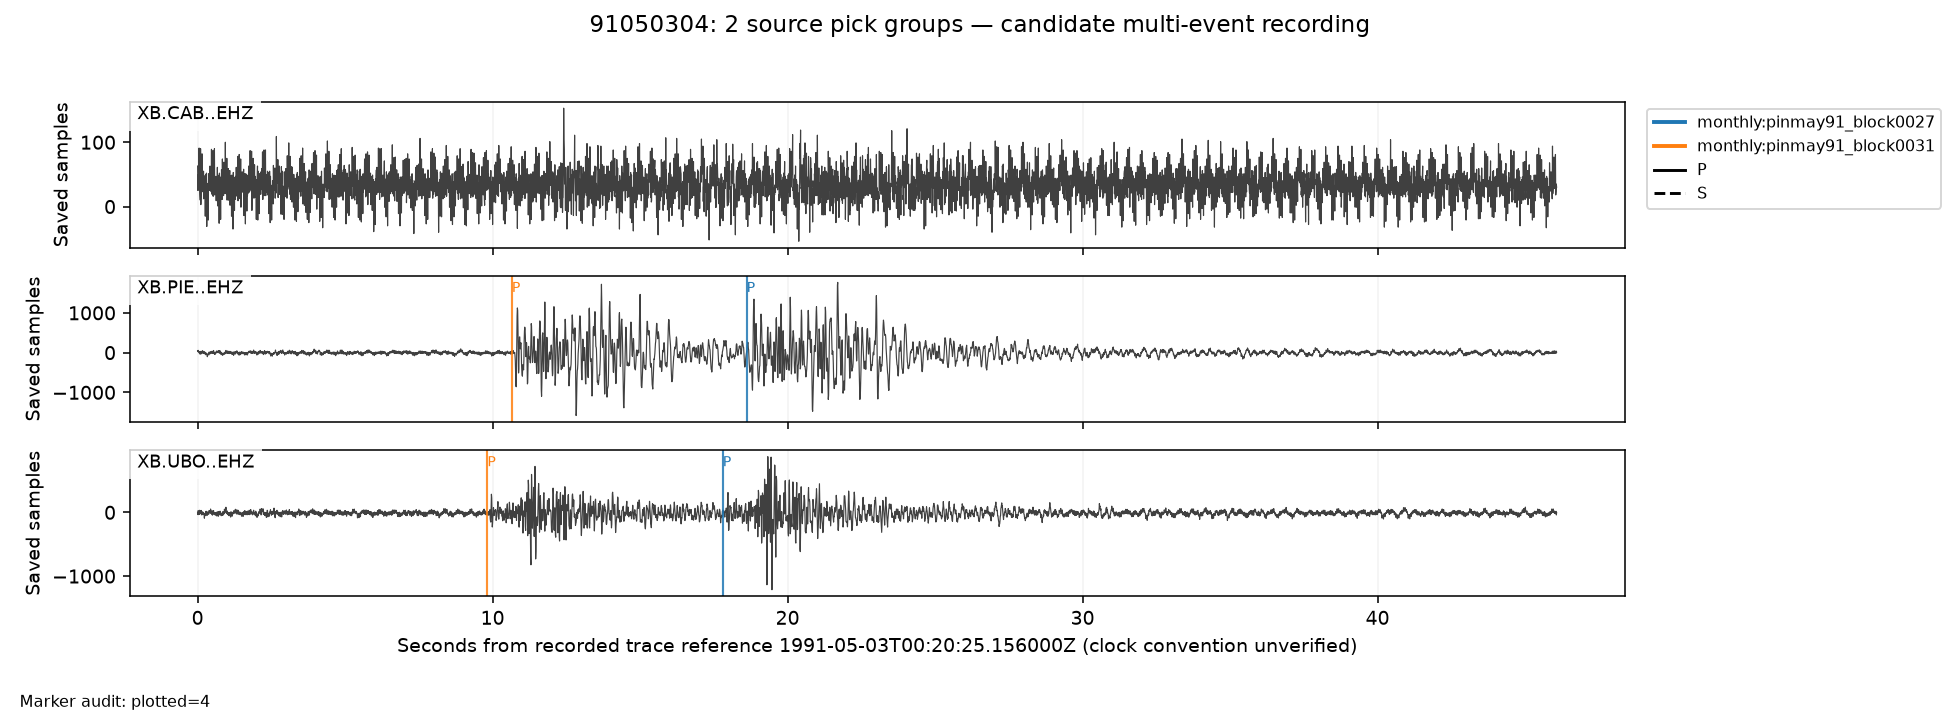

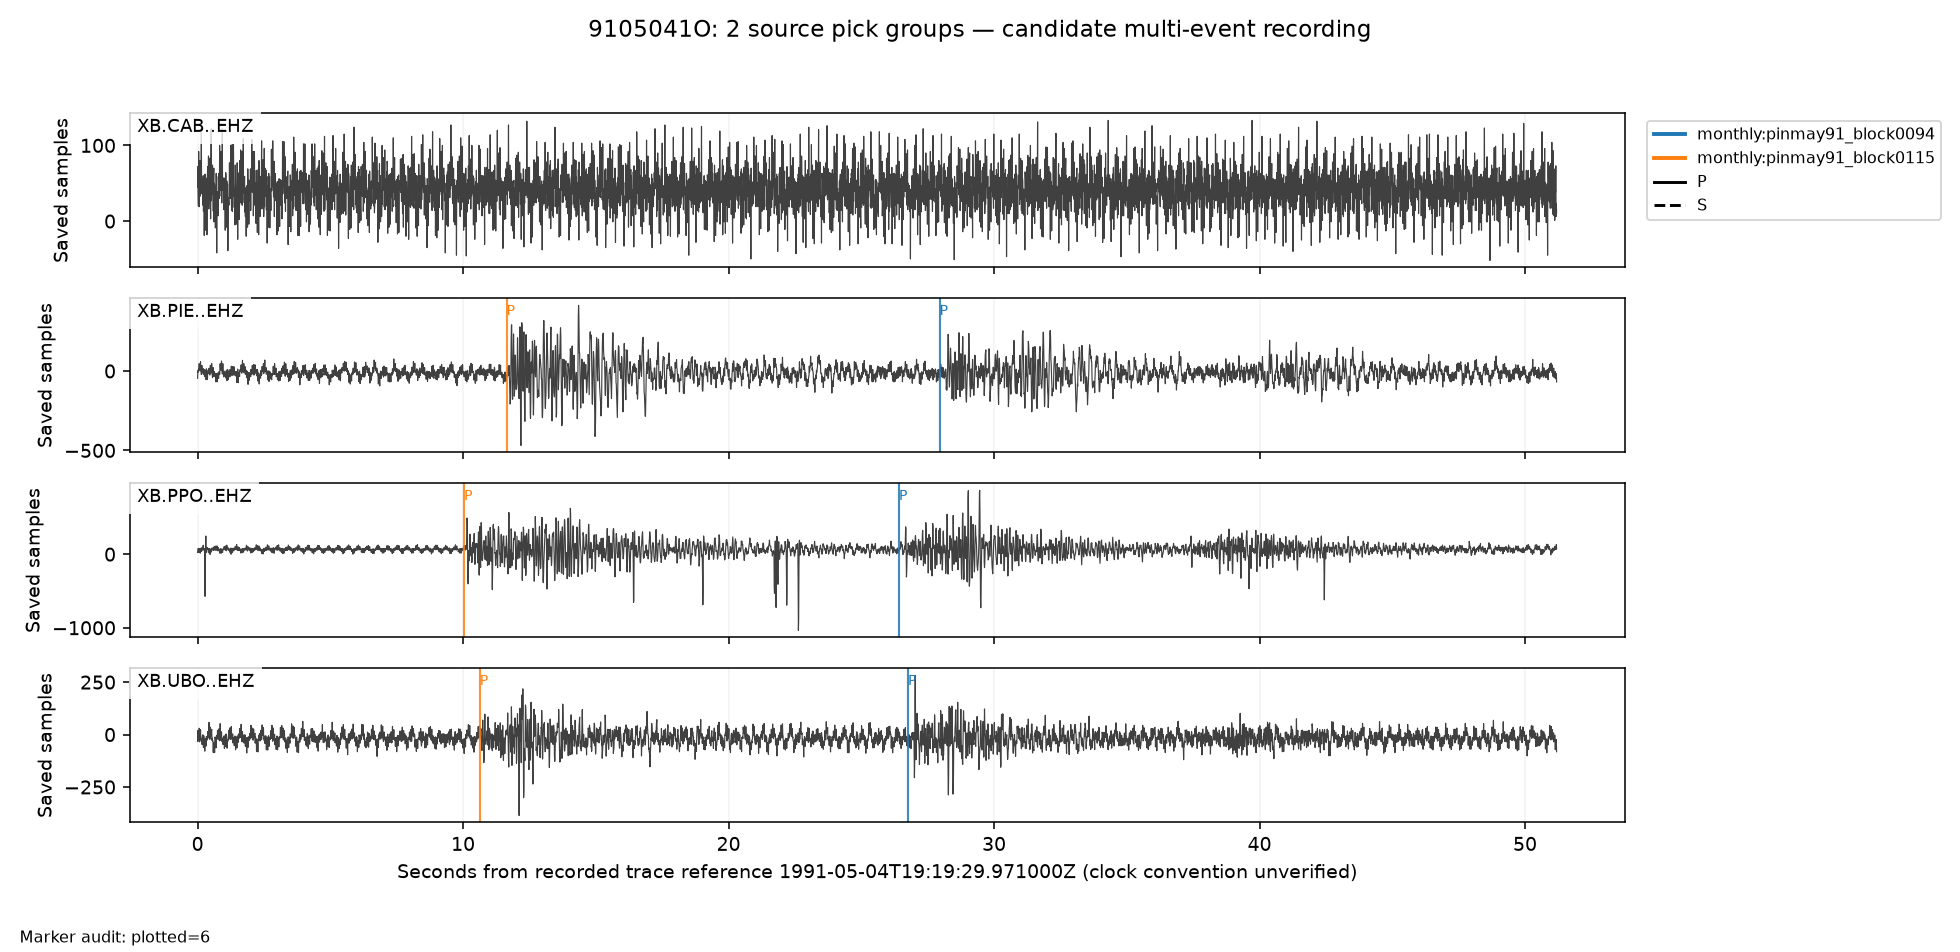

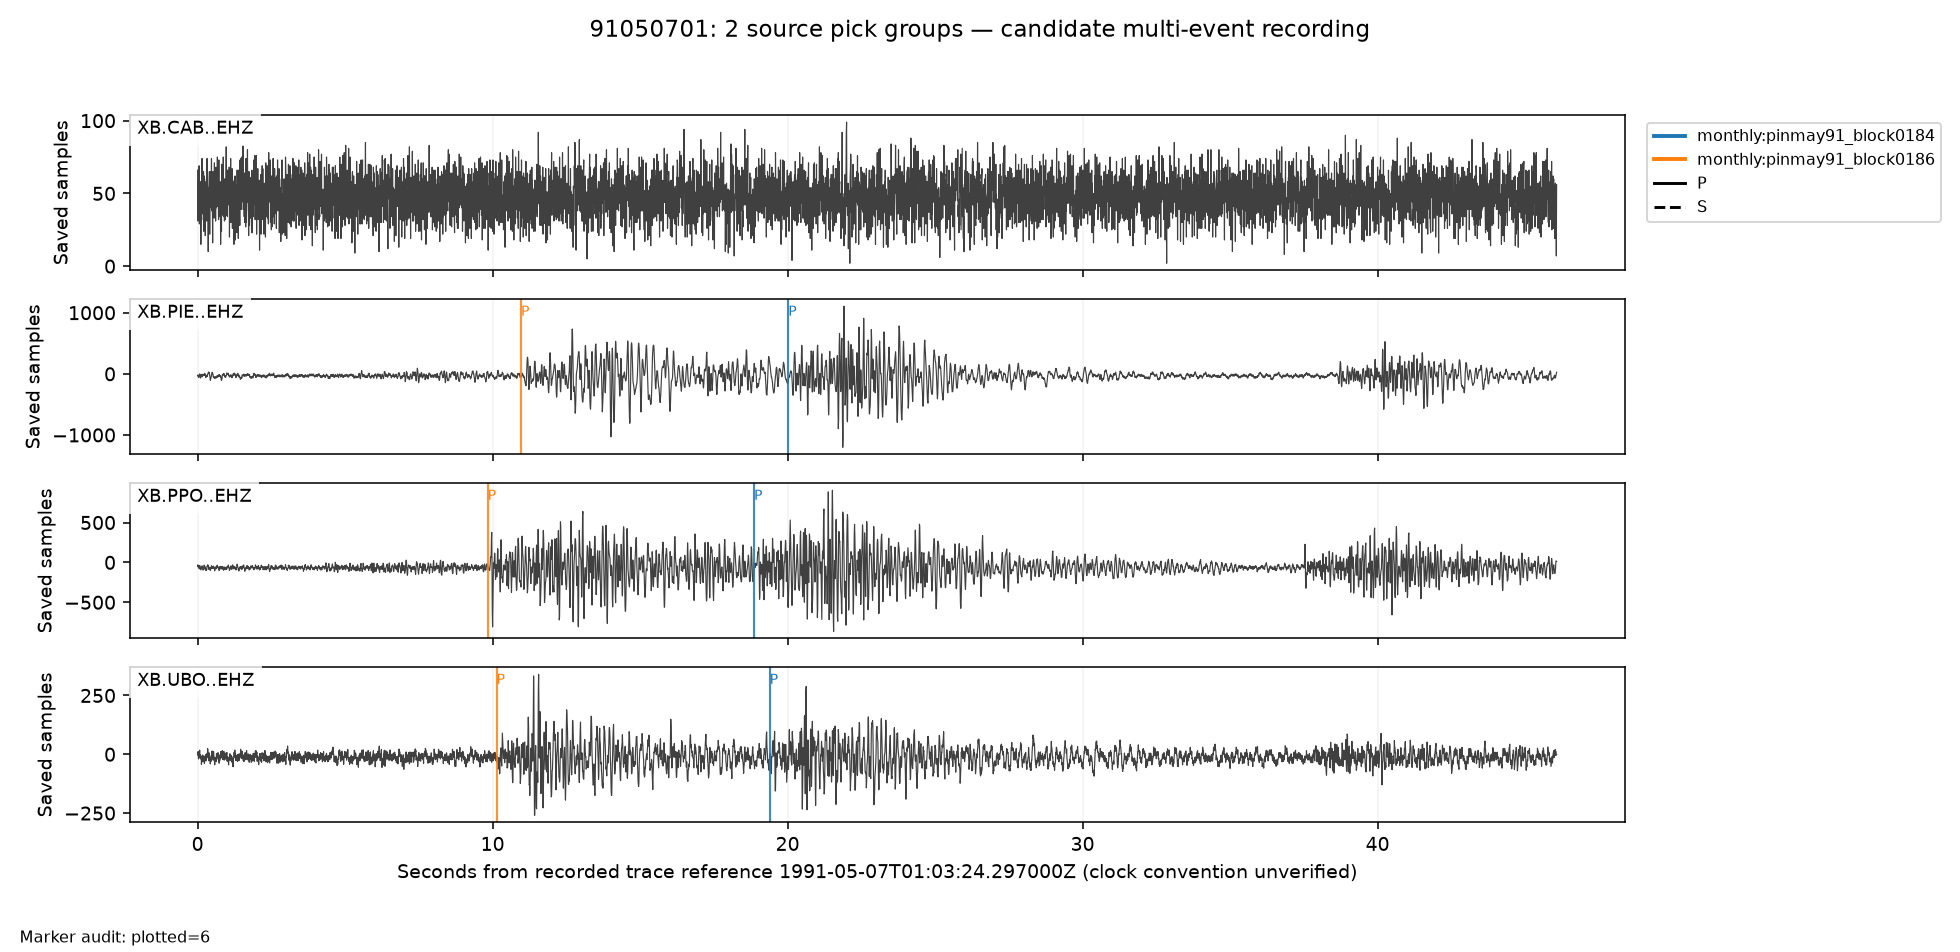

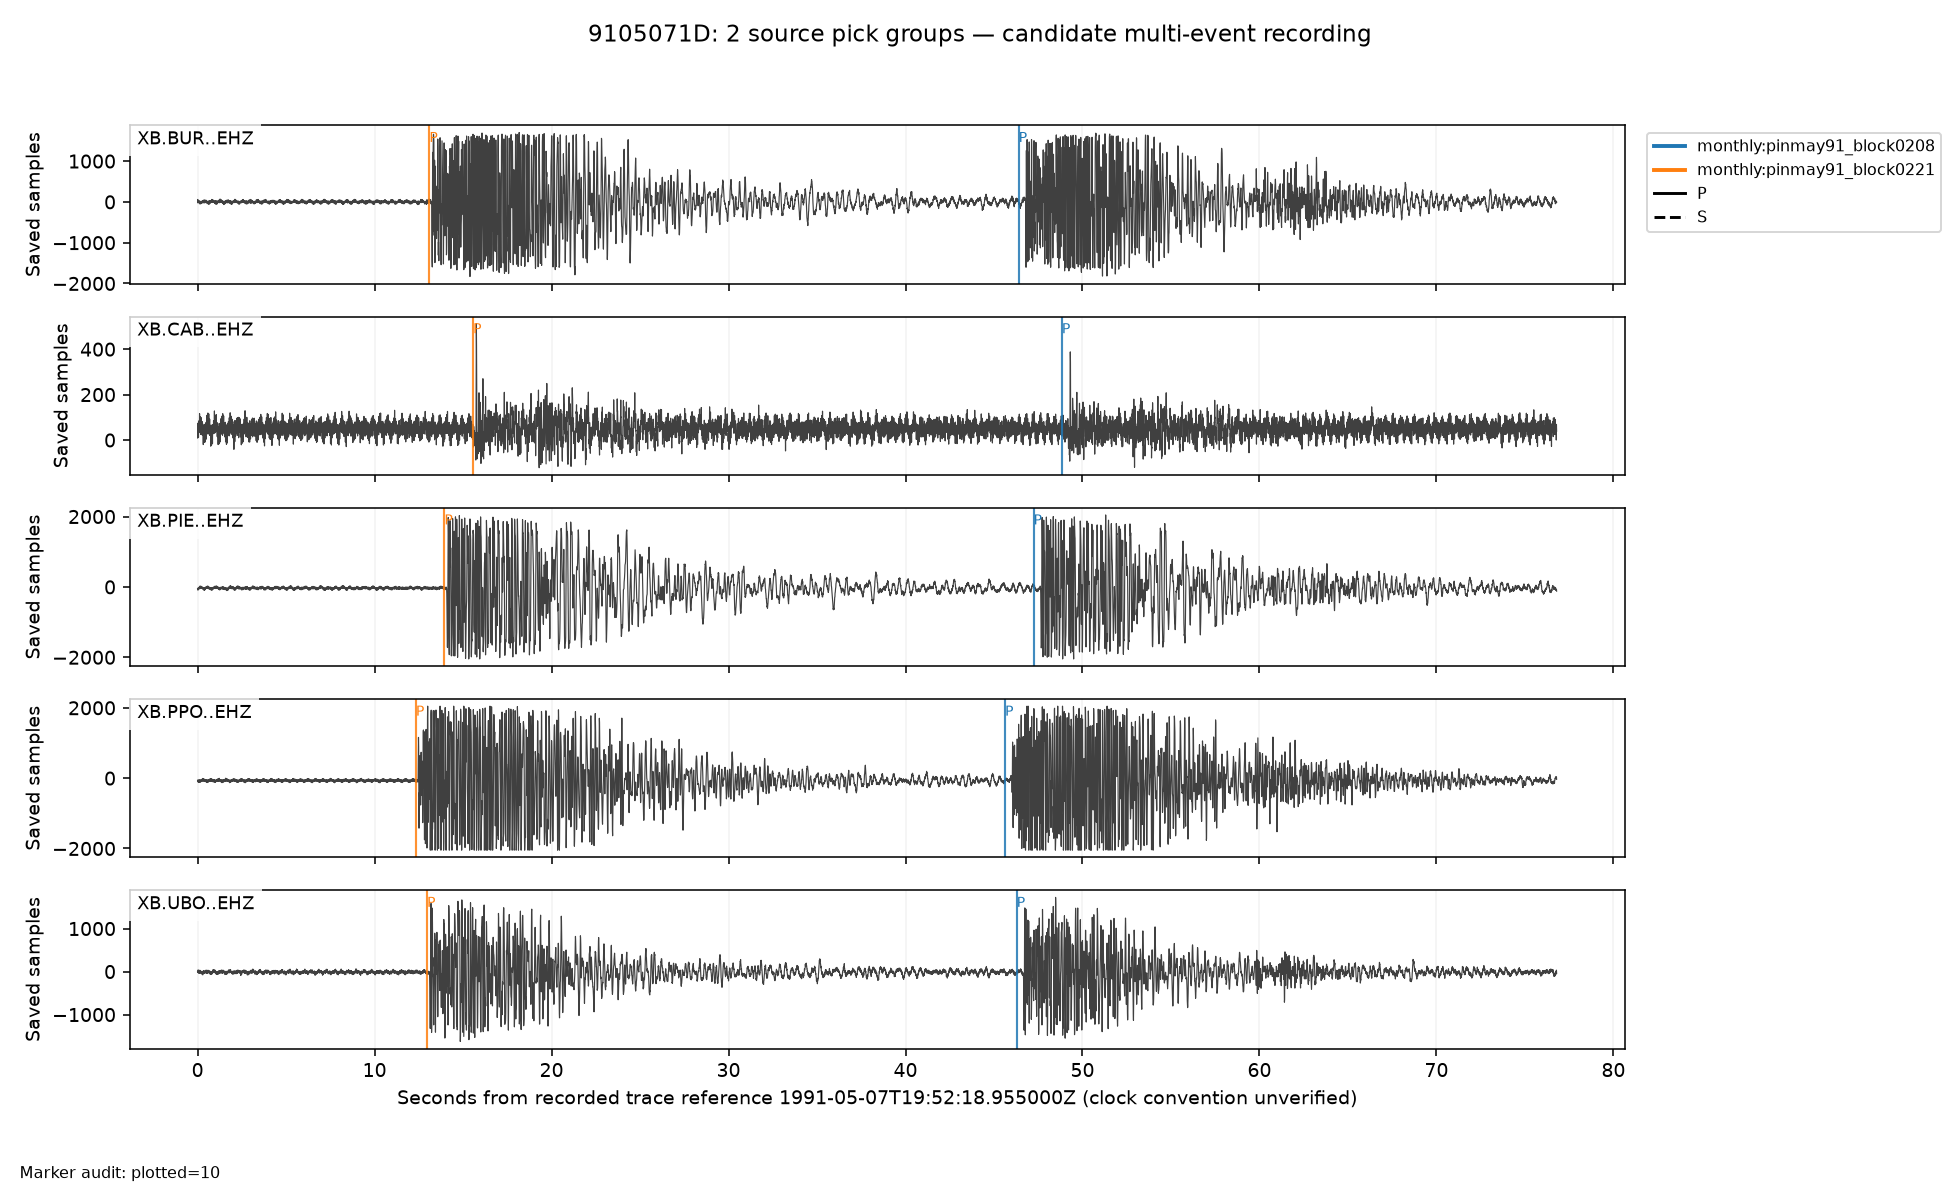

Review files: /Users/thompsong/work/Pinatubo1991Processing/converted/waveform_pick_review/step35/20261111T200642003814Z


,waveform_id,n_pick_groups,n_picks,waveform_file,review_outcome,review_notes,status,plot,pick_audit,plotted_picks,omitted_picks
0,91050304,2,4,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,4,0
1,9105041O,2,6,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,6,0
2,91050701,2,6,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,6,0
3,9105071D,2,10,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,10,0
4,9105071J,2,8,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,8,0
...,...,...,...,...,...,...,...,...,...,...,...
154,9108023Y,2,13,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,13,0
155,91080436,2,15,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,15,0
156,9108044T,2,14,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,12,2
157,9108082N,2,8,/Users/thompsong/work/Pinatubo1991Processing/c...,,,plotted,/Users/thompsong/work/Pinatubo1991Processing/c...,/Users/thompsong/work/Pinatubo1991Processing/c...,8,0


In [4]:
stamp = datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
RUN_DIR = REVIEW_ROOT / stamp
RUN_DIR.mkdir(parents=True, exist_ok=False)
selection.to_csv(RUN_DIR / 'selection.csv')
settings = dict(config_file=str(P['CONFIG_FILE']), pick_map=str(PICK_MAP),
                waveform_index=str(WAVEFORM_INDEX), min_pick_groups=MIN_PICK_GROUPS,
                multiple_within_source=REQUIRE_MULTIPLE_GROUPS_WITHIN_ONE_SOURCE,
                only_waveform_ids=ONLY_WAVEFORM_IDS, max_files=MAX_FILES,
                pick_map_mtime_utc=datetime.fromtimestamp(PICK_MAP.stat().st_mtime, timezone.utc).isoformat(),
                waveform_index_mtime_utc=datetime.fromtimestamp(WAVEFORM_INDEX.stat().st_mtime, timezone.utc).isoformat())
(RUN_DIR / 'run_settings.json').write_text(json.dumps(settings, indent=2) + '\n')
review_rows = []
shown = 0
for waveform_id, selected in selection.iterrows():
    group = review_picks[review_picks['waveform_id'].eq(waveform_id)].copy()
    safe_id = re.sub(r'[^A-Za-z0-9_.-]', '_', str(waveform_id))
    png = RUN_DIR / (safe_id + '.png')
    audit_path = RUN_DIR / (safe_id + '_pick_audit.csv')
    record = dict(waveform_id=waveform_id, n_pick_groups=int(selected['n_pick_groups']),
                  n_picks=len(group), waveform_file=selected.get('wav_file'),
                  review_outcome='', review_notes='')
    try:
        path = selected.get('wav_file')
        if pd.isna(path) or not Path(path).is_file():
            raise FileNotFoundError(f'No current waveform file for {waveform_id}: {path}')
        audit = plot_waveform_groups(path, group, png, dpi=FIG_DPI, save_pdf=SAVE_PDF)
        audit.to_csv(audit_path, index=False)
        record.update(status='plotted', plot=str(png), pick_audit=str(audit_path),
                      plotted_picks=int(audit['review_status'].eq('plotted').sum()),
                      omitted_picks=int(audit['review_status'].ne('plotted').sum()))
        if shown < MAX_INLINE_PLOTS:
            display(Image(filename=str(png)))
            shown += 1
    except Exception as exc:
        record.update(status='error', error=f'{type(exc).__name__}: {exc}')
        group.assign(review_status='waveform_read_or_plot_error').to_csv(audit_path, index=False)
        record['pick_audit'] = str(audit_path)
    review_rows.append(record)
    pd.DataFrame(review_rows).to_csv(RUN_DIR / 'review_index.csv', index=False)
if not review_rows:
    pd.DataFrame(columns=['waveform_id', 'status', 'review_outcome', 'review_notes']).to_csv(RUN_DIR / 'review_index.csv', index=False)
print('Review files:', RUN_DIR)
display(pd.DataFrame(review_rows))

## 5. Interpret and follow up

Start with clearly separated groups in `91060317` and `9106031E`, then examine other selected files. Check whether each group corresponds to a visible arrival sequence, whether monthly/individual groups duplicate one another, and whether picks are on the expected channel. Use the marker audit to investigate everything omitted from the plot. Preserve the uncorrected record and document any proposed edit separately.

Multiple groups alone do not establish multiple earthquakes; one waveform file alone does not establish a single earthquake. This notebook preserves both levels. It does not merge, split, rename or retime scientific events. The next extension can apply the same plotting/audit function to all waveform files with picks, after validating this review subset.